# Project Python Foundations: FoodHub Data Analysis

### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [207]:
# Installing the libraries with the specified version.
!pip install numpy==1.25.2 pandas==1.5.3 matplotlib==3.7.1 seaborn==0.13.1 -q --user

**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.*

In [208]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

### Understanding the structure of the data

In [209]:
# uncomment and run the following lines for Google Colab
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [210]:
# load the dataset
df = pd.read_csv('/content/drive/My Drive/Colab Notebooks/foodhub_order.csv')
df

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24
...,...,...,...,...,...,...,...,...,...
1893,1476701,292602,Chipotle Mexican Grill $1.99 Delivery,Mexican,22.31,Weekend,5,31,17
1894,1477421,397537,The Smile,American,12.18,Weekend,5,31,19
1895,1477819,35309,Blue Ribbon Sushi,Japanese,25.22,Weekday,Not given,31,24
1896,1477513,64151,Jack's Wife Freda,Mediterranean,12.18,Weekday,5,23,31


In [211]:
# Code to view the first 5 rows
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [212]:
# shape returns a tuple of number of rows and columns
df.shape

(1898, 9)

#### Observations: *There are total 1898 rows and 9 columns in the foodhub_order dataset*.


### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [213]:
# info function fetches the datatypes of every column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations: *Dtype column shows the datatypes of different columns in the dataset. There's total 4 object type columns and 5 numerical columns.*


### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [214]:
# checking missing values across each columns
df.isnull().sum() # isnull function checks if there's any null value in any column and then uses sum function to sum them all

,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,0
food_preparation_time,0
delivery_time,0


#### Observations: *There's no null values in the dataset. There's no missing values in any variables or columns. So, there's no need to treat them.*

### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [215]:
# using food_preparation_time column to fetch the preparation time and apply min(), mean() and max() function to get the minimum prepartion time, average and maximum time respectively
df['food_preparation_time'].min()
print('Minimum time: ', df['food_preparation_time'].min())
df['food_preparation_time'].mean()
print('Average time: ', np.around(df['food_preparation_time'].mean(), decimals=2))
df['food_preparation_time'].max()
print('Maximum time: ', df['food_preparation_time'].max())

Minimum time:  20
Average time:  27.37
Maximum time:  35


#### Observations: *The fastest restaurant has ever prepared food was 20 mins and the maximum time it ever took for a restaurant to prepare food was 35 mins. Average time took to prepare food for 1898 orders was 27.37 mins*


### **Question 5:** How many orders are not rated? [1 mark]

In [216]:
# using condition to pull up orders with 'Not Given' rating and then using shape to fetch total number of rows with respective rating from a tupple
print('Unique rating types:', df['rating'].unique())
df[df['rating'] == 'Not given'].shape[0]

Unique rating types: ['Not given' '5' '3' '4']


736

#### Observations: *Out of 1898 orders, there's 736 orders are not rated which is approx ~ 38% orders were Not Given any rating. However the rest were given either 5, 4 or 3 star ratings*


### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

### 1.   Order Id


In [217]:
# Analyze order ids
df['order_id'].nunique()

1898

#### Observation: *There's total 1898 unique order Ids, same number as the total data/rows in the dataset. That being said, order_id data variable looks good with clean data values.*

### 2. Customer Id


In [218]:
# Analyze customer ids
df['customer_id'].nunique()

1200

In [219]:
print(df['customer_id'].value_counts().head())

customer_id
52832     13
47440     10
83287      9
250494     8
259341     7
Name: count, dtype: int64


#### Observation: *There's total 1200 unique customers, that placed orders from the restaurants listed in the dataset. The top most customer has ordered 13 times. And every customer has ordered at least once, so it's safe to say the customer_id data variable is accurate.*

### 3. Restaurant Name

In [220]:
# Analyze restaurant name data variable
df['restaurant_name'].nunique()

178

In [221]:
# display top 5 restaurants wrt to number of orders placed
df['restaurant_name'].value_counts().head()

,count
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68


#### Observation: *There's total 178 unique restaurants. And the top 5 restaurants with respect to the number of orders placed are Shake Shack, The Meatball Shop, Blue Ribbon Sushi, Blue Ribbon Fried Chicken and the Parm.Shake has the most number of orders placed, total 219 which is approx ~ 11% of the total orders in the dataset.*



### 4. Cuisine Type

In [222]:
# Analyze variety of cuisine types
df['cuisine_type'].unique()

array(['Korean', 'Japanese', 'Mexican', 'American', 'Indian', 'Italian',
       'Mediterranean', 'Chinese', 'Middle Eastern', 'Thai', 'Southern',
       'French', 'Spanish', 'Vietnamese'], dtype=object)

In [223]:
# Get the cuisine types in popularity order
df['cuisine_type'].value_counts()

,count
cuisine_type,
American,584
Japanese,470
Italian,298
Chinese,215
Mexican,77
Indian,73
Middle Eastern,49
Mediterranean,46
Thai,19


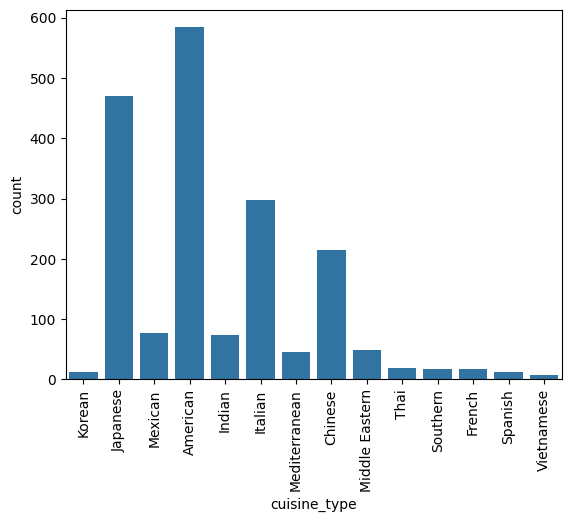

In [224]:
# Observe the number of orders placed for each cuisine type using count plot
sns.countplot(data=df,x='cuisine_type')
plt.tick_params(axis='x', rotation=90)
plt.show()

#### Observation:
* *There's total 14 different types of cuisines in the dataset with American being the most popular one with total 584 orders placed, Japanese the next, followed by Italian, Chinese and Mexican in the top 5 most popular restaurants with respect to the number of orders placed.*
* *Mexican and Indian cuisines are similar in popularity just like Mediterranean and Middle Eastern as seen from the plot.*
* *Korean, Thai, Southern, French and Spanish falls under sam bucket as well, whereas Vietnamese seems like the least favorite one with only 7 orders placed out of 1898 total orders in the dataset.*

### 5. Cost of the order

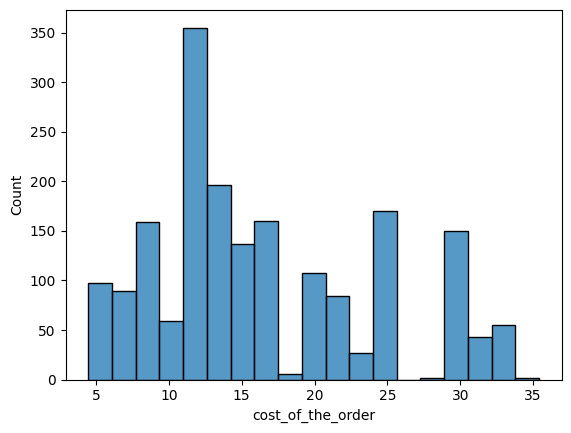

In [225]:
# Histplot for the cost of the order or pricing
sns.histplot(data=df,x='cost_of_the_order');
plt.show()

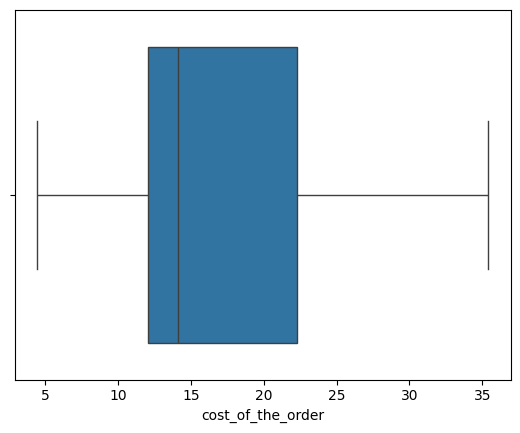

In [226]:
# Bar plot for the cost of the order or pricing
sns.boxplot(data=df,x='cost_of_the_order')
plt.show()

In [227]:
# verifying the median
print('Median of the Cost of the Order is:', df['cost_of_the_order'].median())

# verifying the mean
print('Mean of the Cost of the Order is:', np.around(df['cost_of_the_order'].mean(), decimals=2))

Median of the Cost of the Order is: 14.14
Mean of the Cost of the Order is: 16.5


#### Observation:
*  *As we can see from the histplot, the cost of the 350 orders (approx 18% of the total orders), was from 11 - 13 dollars each.*
* *There's no outliers so it's safe to say that cost of the order data is not abnormal.*
* *The data from the boxplot is skewed on the right with minimum cost of approx 5 dollars to maximum of approx 35 dollars. Meaning the cost of the orders is more on the lower end.*
* *Upper quartile is around 22 while the lower quartile at approx 11 dollars with a median of approx 14 dollars*
* *The avergage cost of the order is ~ $16.5*

### 6. Day of the week

In [228]:
# Anlyze day of the week data variable/column
df['day_of_the_week'].unique()

array(['Weekend', 'Weekday'], dtype=object)

In [229]:
# display unique count values for each day_of_the_week type
df.loc[:, 'day_of_the_week'].value_counts()

,count
day_of_the_week,
Weekend,1351
Weekday,547


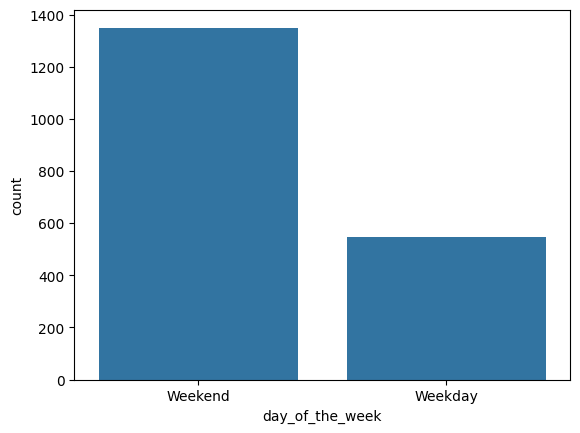

In [230]:
# count plot to analyze the above data
sns.countplot(data=df,x='day_of_the_week')
plt.show()

#### Observation:
*  *We have data for both weekdays and weekends, data variable looks clean with only two possible unique values Weekend and Weekday*
* *Total number of orders placed over weekends are more than over the weekdays, total 1351 ~ 71% of orders were placed over the weekends in comparison to ~ 29% placed over the weekdays*

### 7. Rating

In [231]:
# analyze rating
df['rating'].unique()

array(['Not given', '5', '3', '4'], dtype=object)

In [232]:
# Observe unique values
df['rating'].value_counts()

,count
rating,
Not given,736
5,588
4,386
3,188


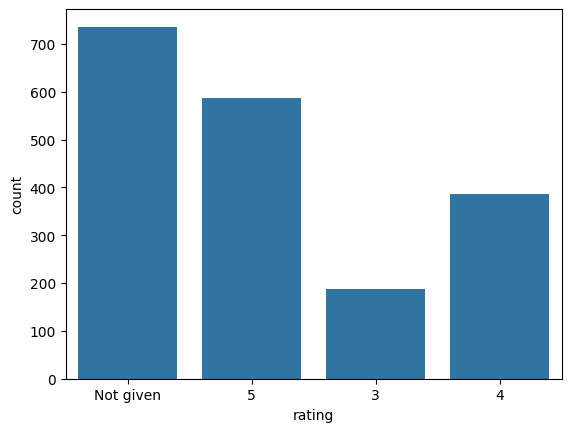

In [233]:
# coountplot for rating column
sns.countplot(data=df,x='rating')
plt.show()

#### Observation:
*  *In the dataset we have 3 unique values for rating variable, one states 'Not given' when customer didn't give any rating to the restaurant they ordered from, and then there's 5s, 4s, and 3,s*
* *Almost ~ 39% of the orders were not given any ratings, howwever ~ 31% were given 5 star rating and only 188 orders with the lowest rating on 3 stars.*
* *Maximum number of orders 736 are not rated, and many factors could be involved in that such as customer might not be satisfied with their order, didn't want to spend extra time rating their order, or simply not interested in sharing their thoughts for the food or the restaurant.*

### 8. Food preparation time

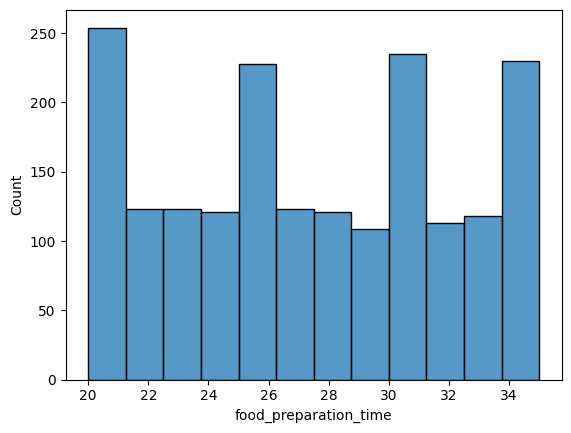

In [234]:
# Analyze food prep time
sns.histplot(data=df,x='food_preparation_time')
plt.show()

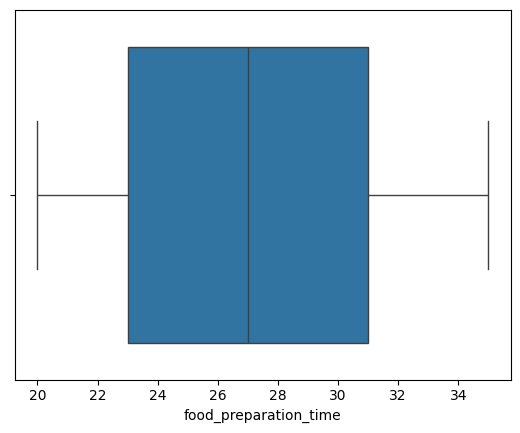

In [235]:
# Boxplot helps analyze food prep time for the accurate median or Q2 as a factor
sns.boxplot(data=df,x='food_preparation_time')
plt.show()

In [236]:
# using food_preparation_time column to fetch the preparation time and apply min(), mean(), median() and max() function to get the minimum prepartion time, average, median and maximum time respectively
df['food_preparation_time'].min()
print('Minimum time: ', df['food_preparation_time'].min())
df['food_preparation_time'].mean()
print('Average time: ', np.around(df['food_preparation_time'].mean(), decimals=2))
df['food_preparation_time'].median()
print('Average time: ', np.around(df['food_preparation_time'].median(), decimals=2))
df['food_preparation_time'].max()
print('Maximum time: ', df['food_preparation_time'].max())


Minimum time:  20
Average time:  27.37
Average time:  27.0
Maximum time:  35


#### Observation:
*  *The above plots seems pretty unformly distributed.*
* *There's no outliers and the median is pretty accurately centered in between lower (23) and upper (31) quartiles, with 20-35 mins range of time.*
* *As verified in the code, the average time when compared to the median, they are almost the same so there's no chance of skewness in the food preparation time.*
* *As we see in the histplot, there's quite ups are downs or so called spikes. Food for approx 250 orders was prepared in about 20-21 mins max, almost 230 orders were prepared in 25-27 mins range and roughly the same number of orders were prepared in the ranges of 30-32 mins and 34-35 mins. Affected factors could be day of the week, or certain type of cuisine, etc.*
* *Overall, there's no severe abnormality in the food preparation time for all the orders in the dataset.*

### 9. Delivery time

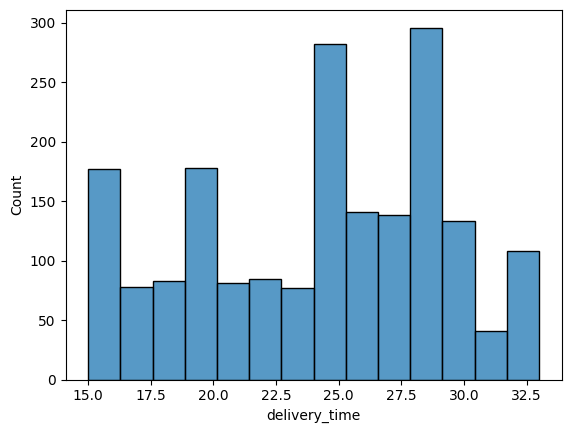

In [237]:
# Analyze delivery time using hisplot bars
sns.histplot(data=df,x='delivery_time')
plt.show()

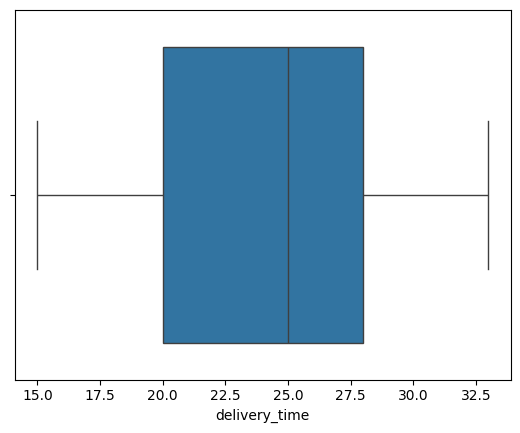

In [238]:
# Analyze delivery time using box plot IQR functionality
sns.boxplot(data=df,x='delivery_time')
plt.show()

In [239]:
# using delivery_time column to fetch the delivery time and apply min(), mean(), median() and max() function to get the minimum delivery time, average, median and maximum time respectively
df['delivery_time'].min()
print('Minimum time: ', df['delivery_time'].min())
df['delivery_time'].mean()
print('Average time: ', np.around(df['delivery_time'].mean(), decimals=2))
df['delivery_time'].median()
print('Median time: ', np.around(df['delivery_time'].median(), decimals=2))
df['delivery_time'].max()
print('Maximum time: ', df['delivery_time'].max())

Minimum time:  15
Average time:  24.16
Median time:  25.0
Maximum time:  33


#### Observation:
*  *The distribution seems close to normal but since the mean is less than the media, the plot is slightly left-skewed, most of the data is on the higher end with a smaller negative values.*
* *Approx 175 orders were delivered in 15-16 mins and 19-20 mins ranges as well.*
* *The most frequent deliveries range in between 28-29 mins for almost 300 orders as seen in the top bins*
* *Since it is slighly negative in skewness, we can say that it takes longer to deliver than usual but other factors like day of the week, cuisine types, etc can matter too*

### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [240]:
# fetching the top 5 restaurants in terms of the number of orders placed by the customers
df['restaurant_name'].value_counts().head()

,count
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68


#### Observations: *'Shake Shack', 'The Meatball Shop', 'Blue Ribbon Sushi', Blue Ribbon Fried Chicken & 'Parm' are the top 5 restaurants with maximum 219 orders placed at the Shake Shack, the fast food chain and minimum of 68 orders placed at the Parm restaurant.*


### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

In [241]:
# fetch the number of orders received over the weekends and compare the cuisine types for all those orders
cusines_by_days = df.groupby('day_of_the_week')['cuisine_type'].value_counts()
cusines_by_days['Weekend']

,count
cuisine_type,
American,415
Japanese,335
Italian,207
Chinese,163
Mexican,53
Indian,49
Mediterranean,32
Middle Eastern,32
Thai,15


#### Observations: *The American cuisine is the most popular one both over the weekends or weekdays with the highest of 415 orders received over the weekends. Japanese is the next popular one with total 335 orders received over the weekends. Korean, Southern and Spanish falls under the same bucket in terms of popularity with 11 orders placed each over the weekends. However, Vietnamese is the least popular among all the cuisines over the weekends.*


### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [242]:
# fetch orders that costed more than $20, calculate percentage
cost_over_20 = df[df['cost_of_the_order'] > 20].shape[0]
percentage_20 = cost_over_20 / df.shape[0] * 100

print('Percentage of orders that cost more than $20: ', np.around(percentage_20, decimals=2), '%', sep='')

Percentage of orders that cost more than $20: 29.24%


#### Observations: *Approx ~ 30% of the orders cost more than $20 dollars*


### **Question 10**: What is the mean order delivery time? [1 mark]

In [243]:
# Fetch the mean of a delivery time using mean function
df['delivery_time'].mean()

24.161749209694417

#### Observations: *The average delivery time to deliver all the orders is approx ~ 24 minutes.*


### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [244]:
# Fetching the total number of value counts for each customer in descending order by default and getting the top 3 customer using head
df['customer_id'].value_counts().head(3)

,count
customer_id,
52832,13
47440,10
83287,9


In [245]:
# Further analysis on the top customer
top_customer = df[df['customer_id'] == 52832]
top_customer.groupby('restaurant_name')['customer_id'].count()

,customer_id
restaurant_name,
Dickson's Farmstand Meats,1
Don's Bogam BBQ & Wine Bar,1
Donburi-ya,3
Dos Caminos,1
Han Dynasty,2
Junoon,2
L'Express,1
ilili Restaurant,2


#### Observations: *The customers with customerId '52832', '47440' and '83287' are the top 3 customers in terms of maximum number of orders placed. Top customer has placed the highest orders, total 13 from 8 different restaurants with 'Donburi-ya' as their favorite with most orders placed*


Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


### 1. Relationship between numerical variables

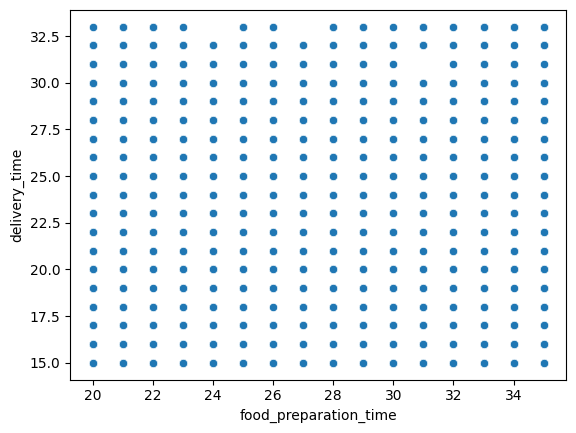

In [246]:
# Show relationship between both food prep and delivery times using scatter plot
sns.scatterplot(data=df,x='food_preparation_time',y='delivery_time')
plt.show()

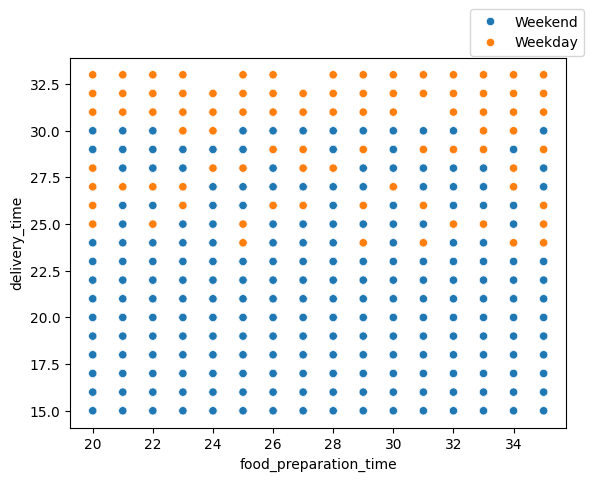

In [247]:
# Show relationship between both food prep and delivery times using scatter plot present with day of the week color

sns.scatterplot(data=df,x='food_preparation_time',y='delivery_time', hue='day_of_the_week')
plt.legend(bbox_to_anchor=(1.05, 1.15), loc='upper right')
plt.show()

*There's no significant correkation between food preparation time and delivery time.*

*Looks like delivery time depends more on external factors than preparation time, there could be natural variation like for 31 mins of delivery time might be very rare for food to be preparated in that long time duration.*

*We can see food delivery times over the weekdays are higher generically for any time it took prepare the food, other factors like traffic and less frequent orders could also play some role here*

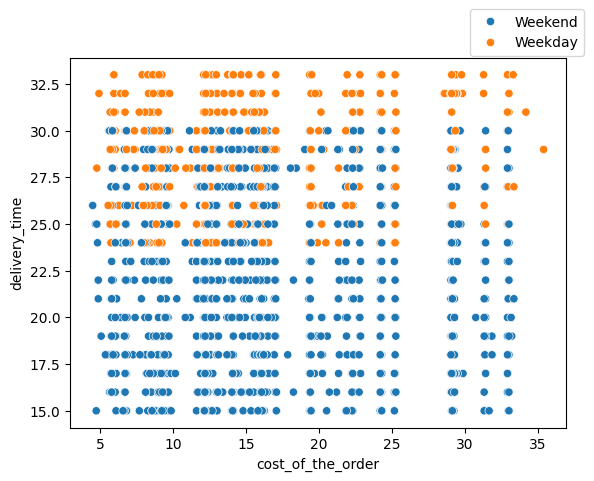

In [248]:
# Show relationship between both cost and delivery time using scatter plot

sns.scatterplot(data=df,x='cost_of_the_order',y='delivery_time', hue='day_of_the_week')
plt.legend(bbox_to_anchor=(1.05, 1.15), loc='upper right')
plt.show()

*There's no strong correlation between cost and delivery times, higher cost orders don't consistently have longer or shorter delivery times and same with lower cost orders.*

*Orders placed over the weekdays are slower in deliveries in comarison to the orders placed over the weekends, they are most widely spreaded across all the delivery times but lower than over the weekdays.*

*You can see few outliers on weekdays, it took ~28 mins to deliver the most expensive food dish worth ~ $35 and over all they have more than ~33 mins of delivery time for pretty much any cost of the order in form of outliers.*

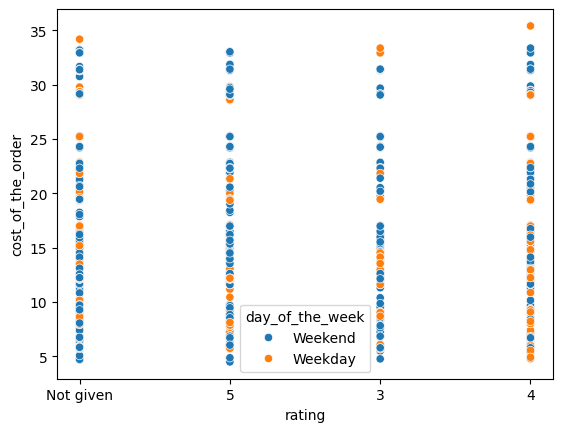

In [249]:
# cleaning rating column to use rating values more accurately and feeding into new dataframe
rating_numeric = df.loc[df['rating'] != 'Not given']

# Show relationship between both cost  and rating using scatter plot
sns.scatterplot(data=df,y='cost_of_the_order',x='rating', hue='day_of_the_week')
plt.show()

*There's no severe correlation between rating and the cost of the orders.*
*Most of the ratings weren't given over the weekends. Whereas most of the max/5 star ratings were given over the weekends for the expensive orders with some possible outliers and only a couple extremely expensive were ordered over the weekdays with the highest rating.*

*There's one noticable outlier, order with more than ~ $35 were given 4 star rating over the weekdays.*

*Customers are willing to rate the restaurants more over the weekdays as seen in the cluster at 4 star rating than over the weekends, that could also mean the number of orders placed over the weekends is lot more than over the weekdays.*

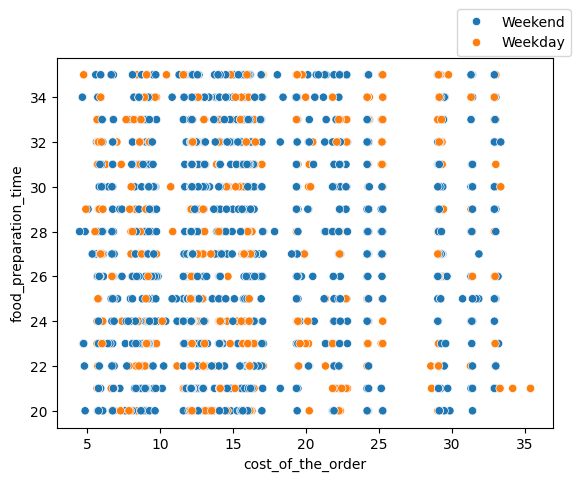

In [250]:
# Show relationship between both food prep times and cost using scatter plot present for both weekdays and weekends

sns.scatterplot(data=df,x='cost_of_the_order',y='food_preparation_time', hue='day_of_the_week')
plt.legend(bbox_to_anchor=(1.05, 1.15), loc='upper right')
plt.show()

*There's definitely no tight relationship betwen cost and preparation time due to other factors playing role like cuisine type, efficiency, etc..*

*However, we can say weekend orders are on an average more expensive than weekday orders and take longer time to prepare possibly due to higher demand over the weekends.*

*Noticeably there are few outliers though such as weekday orders with a cost of around 30-15 dollars takes only 20-22 minutes to prepare food, which is unusually short for such a high costs.
Similarly, there are weekend orders with costs around 5-10 dollars and preparation times around 20-24 mins, ~28 mins or ~30 mins, which is unusually long for low-cost orders.*

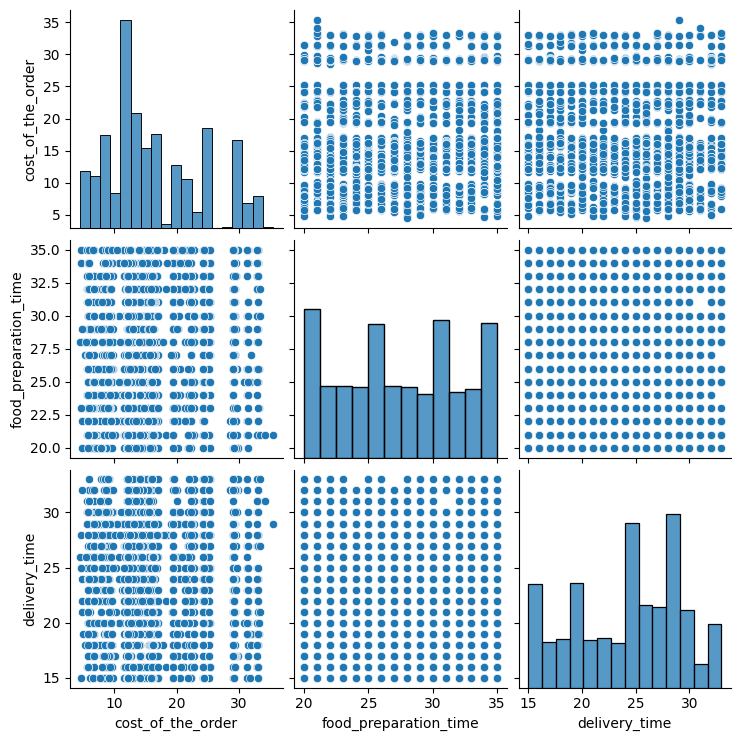

In [251]:
# Show relationship between both food prep times and cost, combine using pair plots

sns.pairplot(df[['cost_of_the_order', 'food_preparation_time', 'delivery_time']])
plt.show()

*The cost of order distibution shows peak arounf 20-25 dollars with significant number of orders within 15-30 dollars range. Fewer orders fall below 10 dollars or above 30 dollars, indicating orders are moderately priced.*

*Most order takes 20-25 mins to prepare, with fewer taking less than 25 mins or more than 32 mins*

*Most deliveries take 20-25 mins, with fewer taking less than 20 mins or more than 27 mins.*

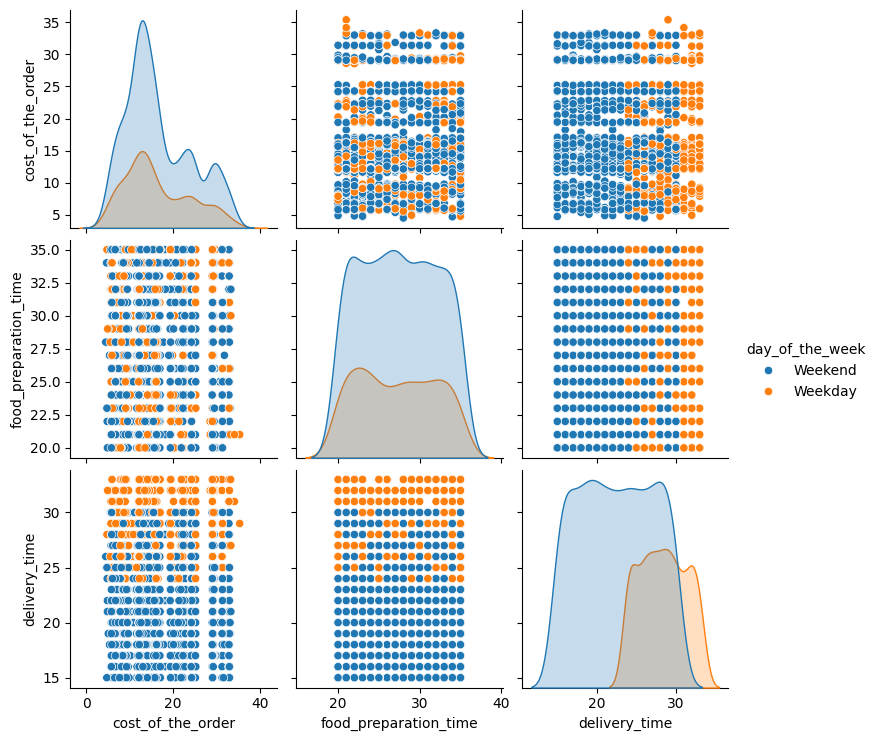

In [252]:
# Combine all three numerical data variables food prep and delivery times with cost and present for both weekdays and weekends using pairplot
sns.pairplot(data=df, vars=['cost_of_the_order', 'food_preparation_time', 'delivery_time'], hue='day_of_the_week')
plt.show()

*Looks like weekends experience higher demand, leading to more expensive orders, longer prep imes and longer delivery times, could be due to social gatherings, activities, etc.*

*Weekdays, in contrast may involve routine, lower-cost orders with shorter prep and delivery times, possibly reflecting lower demand or simpler logistics*

*Lack of strong correlation between numerical variables could be due to factors like traffic, kitchen efficiency, order complexity, weather, etc beyond just the day of the week or cost*

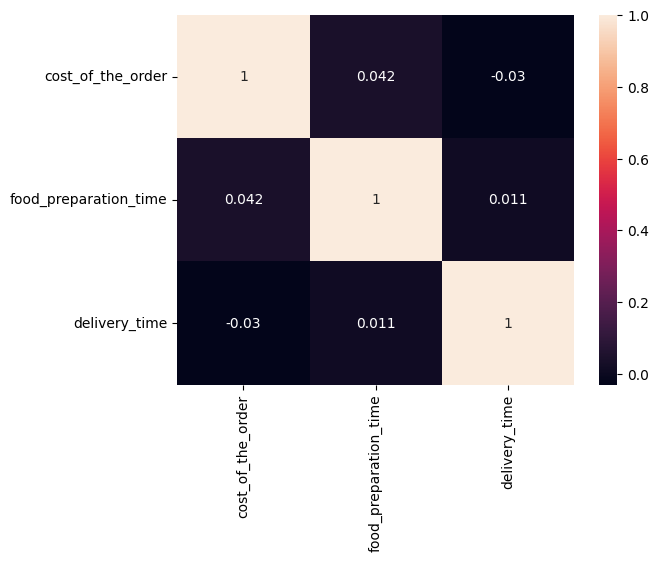

In [253]:
# correlation matrix
correl_matrix = df[['cost_of_the_order', 'food_preparation_time', 'delivery_time']].corr()

# display heatmap with correl matrix data for all three numerical data variables
sns.heatmap(correl_matrix, annot=True)
plt.show()

*All of diagonla correlations are very close to 0 indicating no significant linear relationships between all three variables*

*Week positive correlations (0.042 and 0.011) suggests tiny tendency for higher costs or longer prep time to be slightly associated with longer delivery times but it's negligible*

*Week negative correlation (-0.03) suggests an almost imperceptible tendency for higher-cost orders to have slightly shorter delivery times, but this relation between cost of the orders and delivery times is also negligible*

### 2. Relationship between numerical and categorical data

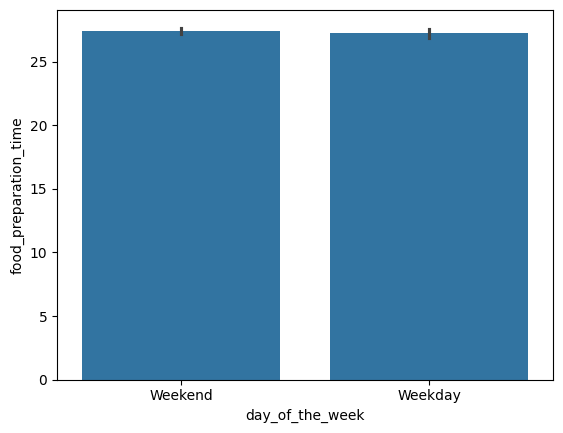

In [254]:
# Analyze correlation bwtween day of the week and food prep time
sns.barplot(data=df,x='day_of_the_week',y='food_preparation_time')
plt.show()

*Similarity in the bars suggests avg food prep time is roughly same for the weekdays and weekends.*

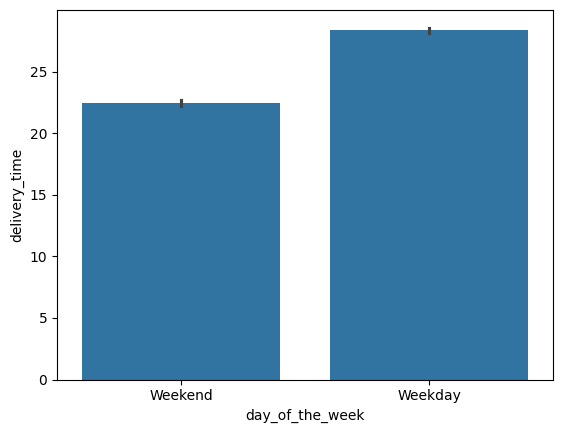

In [255]:
# Analyze correlation between day of the week and food delivery time
sns.barplot(data=df,x='day_of_the_week',y='delivery_time')
plt.show()

*This chart clearly suggests that average delivery times are longer over the weekdays compared to weekends, could be due to traffic, demand, logistical challenges over weekdays, etc.*

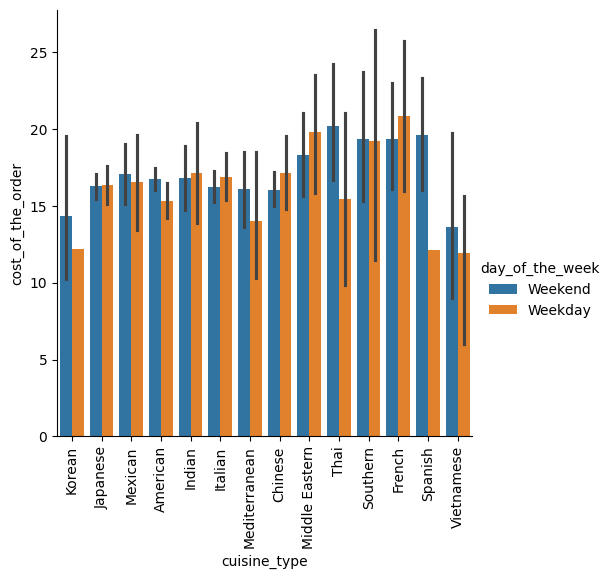

In [256]:
# Analyze correlation between cuisine (categorical )and the price (numerical) using cat plot

sns.catplot(data=df,x='cuisine_type',y='cost_of_the_order', kind="bar", hue='day_of_the_week')
plt.xticks(rotation=90)
plt.show()

*Most cuisines have similar cost distributions, with medians around 15-20 dollars and moderate variability. However Southern stands out with higher median and wider vriability, possibly due to more expensive ingredients or size of the meal.*

*Vietnames and korean have significntly lower costs maybe due to simple menus, smaller portions like fast-food size, etc.*

*Outliers in several cuisines indicate occassional high-cost orders, possibly for special dishes, larger group size, etc. especially for the Korean, Japaneese and Mediterranean.*

*Weekdays tend to have slightly higher or more variable costs than weekends for many cuisines.*



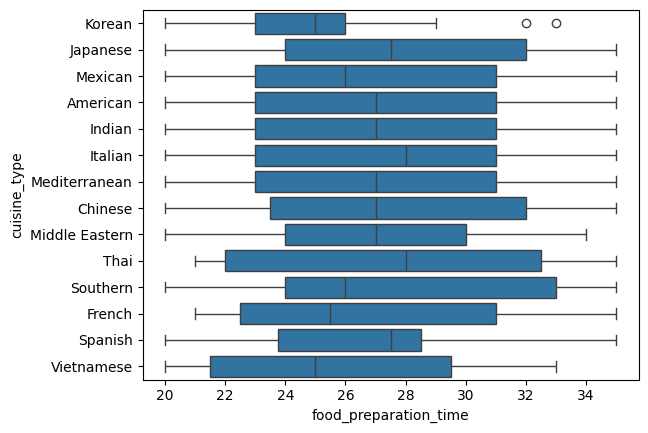

In [257]:
# Analyze correlation between cuisine and food prep time
sns.boxplot(data=df,y='cuisine_type',x='food_preparation_time');
plt.show()

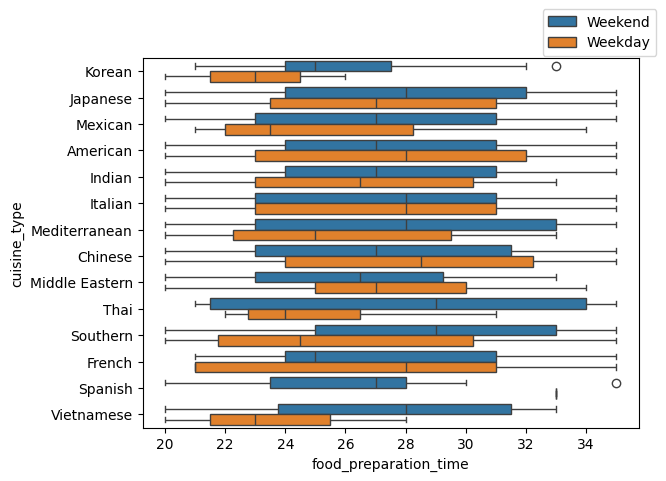

In [258]:
# Analyze correlation between cuisine and food prep time, with day of the week attribute
sns.boxplot(data=df,y='cuisine_type',x='food_preparation_time', hue='day_of_the_week')
plt.legend(bbox_to_anchor=(1.05, 1.15), loc='upper right')
plt.show()

*Data suggests that most cuisine types take around 26-28 mins to prepare on average, with Thai & Southern taking the longest time to prepare food, while Korean and Vietnamese taking the shortest time.*

*Moderate IQR/variability indicates that preparation times are relatively consistent for each cuisine type, except for the exception like outliers in Korean cuisine time due to some rare order with rare meal that took unsually longer to cook.*

*To be specific with the day of the week, the outliers on weekends for Korean and Japanese suggest rare delays, potentially due to special requests or operational challenges on busier days.*

*Longer prep times on weekends could reflect higher demands, while weekdays show shorter and more consistent tmes, possibly due to lower demand on simpler orders.*


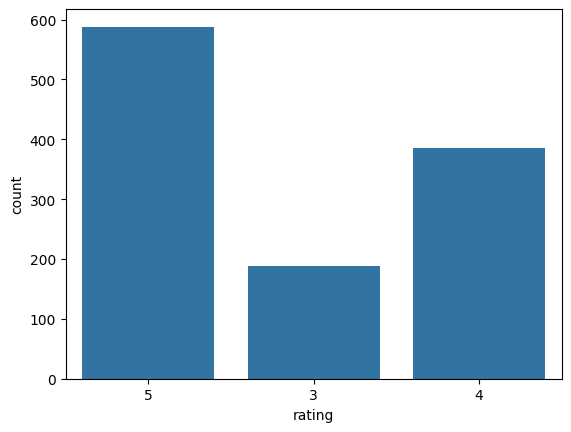

In [259]:
# For the data accuracy and higher predictability, removing the 'Not Given' rating temporarily
rating_numeric = df.loc[df['rating'] != 'Not given']
sns.countplot(data=rating_numeric,x='rating')
plt.show()

*Data suggests high customer satisfaction, as the vast majority of ratings are 4 or 5, very few at 3. That means overall, food delivery service, restaurant or the food being rated performs well.*

*Note we have only 5,4, and 3 ratings data, that means it mainly focuses on positive feeback.*

*Higher frequency of 5-star ratings compared to 4-star suggests that mostt customers are extremely satisfied, whereas disatisfction with 3-star ratings is not a significant issue in the dataset with less satisfied customers being rare.*

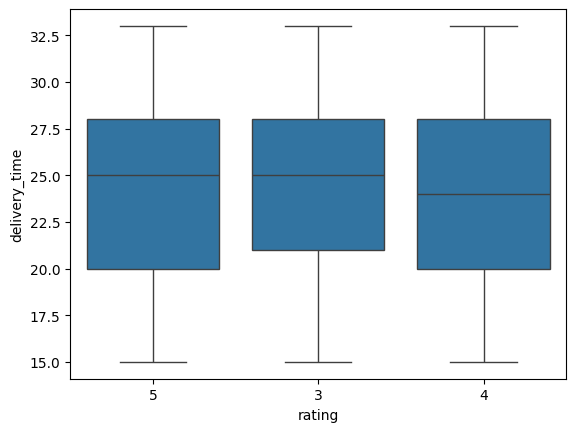

In [260]:
# Analyze relationship between rating and delivery time
sns.boxplot(data=rating_numeric,x='rating',y='delivery_time')
plt.show()

In [261]:
# Converting the rating column in rating_numeric dataframe to get the accurate median for comparison
rating_numeric.loc[:, 'rating'] = pd.to_numeric(rating_numeric['rating'])
rating_numeric.groupby('rating')['delivery_time'].median()

,delivery_time
rating,
3,25.0
4,24.0
5,25.0


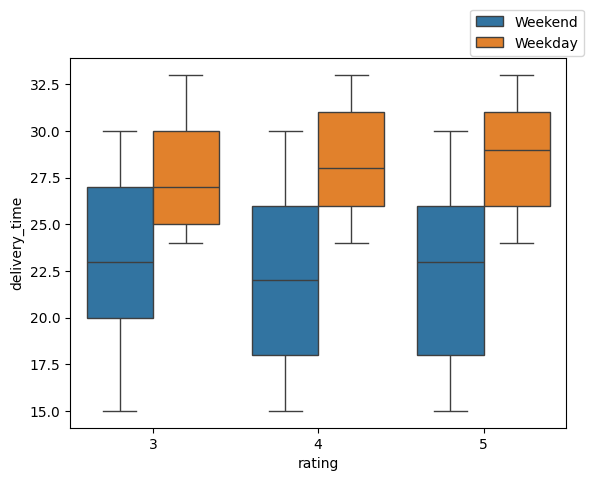

In [262]:
# Analyze relationship between rating and delivery time with color attribute as day of the week
sns.boxplot(data=rating_numeric,x='rating',y='delivery_time', hue='day_of_the_week')
plt.legend(bbox_to_anchor=(1.05, 1.15), loc='upper right')
plt.show()

*Lack of significant variation in delivery times across ratings means that the service maintains a stable delivery performance, but customer satisfaction varies due to other aspects.*

*There are no visible outliers and the difference in the median between 3 & 5 and 4 is not significant.*

*There's a caveat though, delivery times are slightly longer over the weekdays bc the median delivery time is higher than over weekends*

*Similarly, weekday delivery times have lower IQR compared to weekend, indicating less variability in delivery times for weekdays across all the ratings*

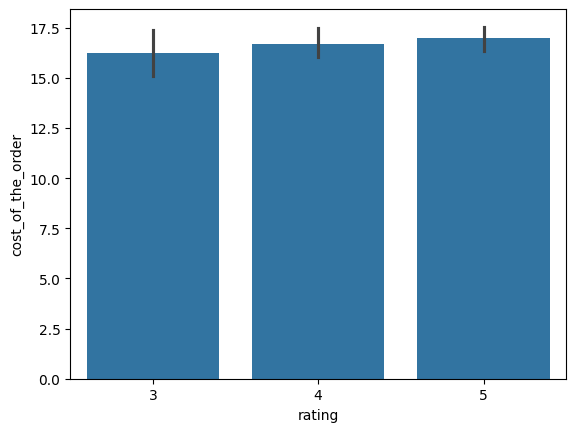

In [263]:
# Analyze correlation between cost and rating
sns.barplot(data=rating_numeric,x='rating',y='cost_of_the_order')
plt.show()

*Cost of the order doesn't correlate with the rating or has nearly no significant impact.*

### 3. Relationship among categorical data variables

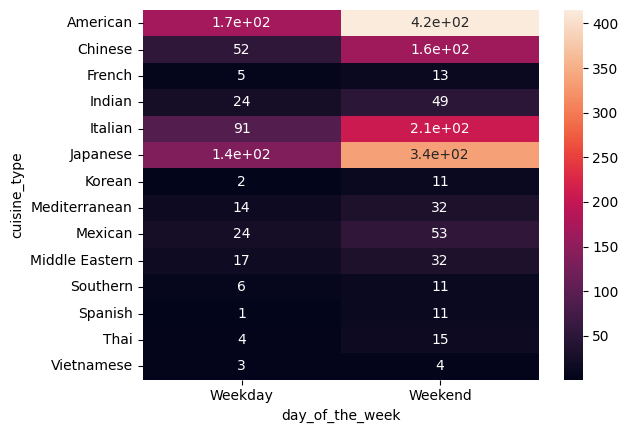

In [264]:
# Perform cross-tabulation across cuisine and day of the week then analyze using heatmap
crosstab = pd.crosstab(df['cuisine_type'], df['day_of_the_week'])
crosstab
sns.heatmap(crosstab, annot=True)
plt.show()

*Italian, American, Chinese and Japanese cuines have the highest absolute values suggesting the most popular overall.*

*Spanish cuisine shows most dramatic increase while Vietnames has the smallest.*

*Across nearly all cuisines there's consistent increase in orders over weekends*

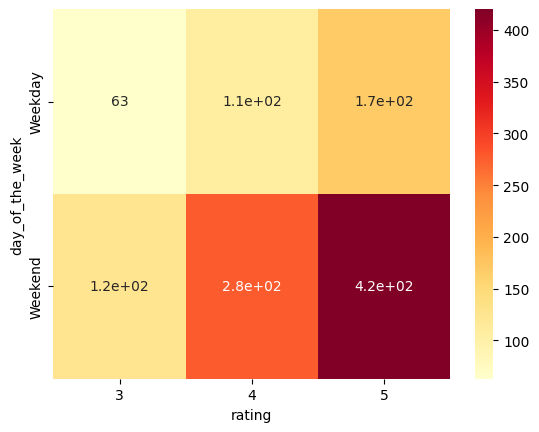

In [265]:
# Perform cross-tabulation across day of the week and rating and then analyze using heatmap
crosstab = pd.crosstab(df['day_of_the_week'], rating_numeric['rating'])
crosstab
sns.heatmap(crosstab, annot=True, cmap='YlOrRd')
plt.show()

*Across all rating levels, weekend trends are consistently higher with much larger absolute numbers*

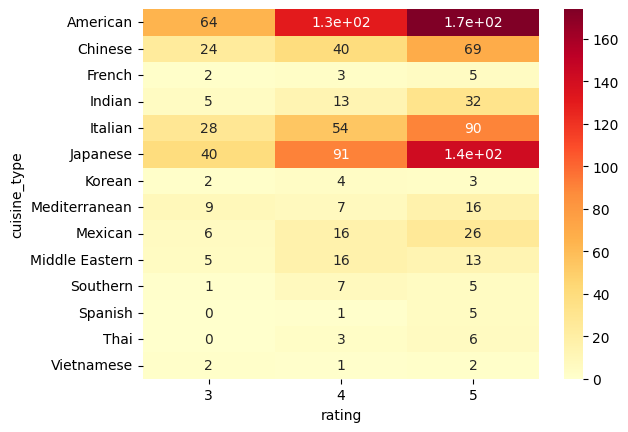

In [266]:
crosstab = pd.crosstab(df['cuisine_type'], rating_numeric['rating'])
crosstab
sns.heatmap(crosstab, annot=True, cmap='YlOrRd')
plt.show()

*American and Japanese cuisines consistently rank highest across both 4 and 5 ratings, they are highly favored or well regarded.*

*Cuisines with zero counts like Spanish, Thai doesn't have many ratings and they are poorly rated*

*There's correlation between higher counts and higher ratings, but some cuisines perform moderately despiite lower representation like Mexican with 16 4-star ratings, which is in between 3-star and 4-star with 6 and 26 counts respectively.*

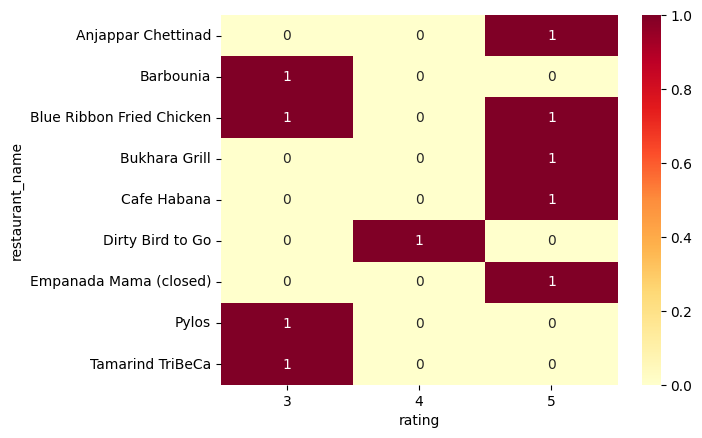

In [267]:
# Just using some of the restaurants to show association with the ratings
crosstab = pd.crosstab(df['restaurant_name'].head(15), rating_numeric['rating'])
crosstab
sns.heatmap(crosstab, annot=True, cmap='YlOrRd', fmt='d')
plt.show()

*Pylos, Tamarind, Blue Ribbon Fried Chicken and Barbounia are strongly associated with 3-star ratings, Dirty Bird To Go with 4-star and the rest are 5-star rating.*

### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [268]:
# Creating a copy of original dataset since we need to manipulate the rating column
df_copy = df.copy()

# fetching the string "Not Rating" rating type out of the rating variable to manipulate on actual ratingsdf_rating = df_copy[df_copy['rating'] != 'Not given']
df_rating = df_copy[df_copy['rating'] != 'Not given']

# converting the rating variable to numeric datatype to convert numeric ratings from string to appropriate numeric datatype
df_rating.loc[:, 'rating'] = pd.to_numeric(df_rating['rating'])

# GroupBy will fetch the restaurants with both number of rating counts and mean of those ratings using aggregate function
restaurant_ratings = df_rating.groupby(['restaurant_name'])[['rating']].agg(['count', 'mean']).reset_index()

# fetching the restaurants with total ratings more than 50 and the average rating greater than 4
result = restaurant_ratings[(restaurant_ratings[('rating', 'count')] > 50) & (restaurant_ratings[('rating', 'mean')] > 4)]

result.sort_values(by=[('rating', 'count')], ascending=False)


restaurant_name rating          
                                count      mean
117                Shake Shack    133  4.278195
132          The Meatball Shop     84  4.511905
17           Blue Ribbon Sushi     73  4.219178
16   Blue Ribbon Fried Chicken     64  4.328125

#### Observations: *There's only four out of 178 restaurants with total ratings more than 50, Shake Shack with the highest number of ratings 133, The Meatball Shop with 84 ratings, Blue Ribbon Sushi restuarant had 73 ratings in total and Blue Ribbon Fried Chicken with 64 in total. All four of them has rating of more than 4 ratings with The Meatball Shop with higest average ratings of ~ 4.5.*


### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [269]:
# prompt: Using dataframe df: The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders.

# Calculate revenue for orders greater than $20
revenue_20 = df[df['cost_of_the_order'] > 20]['cost_of_the_order'] * 0.25

# Calculate revenue for orders greater than $5 but less than or equal to $20
revenue_5 = df[(df['cost_of_the_order'] > 5) & (df['cost_of_the_order'] <= 20)]['cost_of_the_order'] * 0.15

# Calculate total revenue
total_revenue = sum(revenue_20) + sum(revenue_5)

# Print or return the result
print('Number of orders with more than $20 cost:', df[df['cost_of_the_order'] > 20].shape[0])
print('Number of orders between $5 to $20 cost:', df[(df['cost_of_the_order'] > 5) & (df['cost_of_the_order'] <= 20)].shape[0])
print("Number of orders that don't benefit the company:", df[df['cost_of_the_order'] <= 5].shape[0])
print('The net revenue generated by the company is: ', '$', np.around(total_revenue, decimals=2), sep='')

Number of orders with more than $20 cost: 555
Number of orders between $5 to $20 cost: 1334
Number of orders that don't benefit the company: 9
The net revenue generated by the company is: $6166.3


###Observations: *The net revenue generated by the company across all the 1898 orders is 3865.57 dollars. That means company made revenue on just ~ 60% of the total orders and the rest ~ 40% of orders cost below $5 each.*

### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [270]:
longer_orders = df[df['food_preparation_time'] + df['delivery_time'] > 60]
percentage = longer_orders.shape[0] / df.shape[0] * 100
print('Percentage of orders that takes more than 60 minutes are: ', np.around(percentage, decimals=2), '%', sep='')

Percentage of orders that takes more than 60 minutes are: 10.54%


#### Observations: *So approx ~ 11% of the orders took more than 60 minutes since the time orders were received from the customers. It is still safe to say almost 90% of the orders didn't fail to deliver within 60 minutes of timeframe in any condition whether it's weekday or weekend.*


### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

In [271]:
# Checking the mean delivery time of the orders on weekdays and weekends
df.groupby('day_of_the_week')['delivery_time'].mean()

,delivery_time
day_of_the_week,
Weekday,28.340037
Weekend,22.470022


#### Observations: *Deliveries take longer on weekdays compared to weekends. Food is delivered about ~6 minutes faster on an average over the weekends than over the weekdays. The impacting factors could be higher weekday demand, traffic, rush-hours, or staffing variations while weekends might be smoother or less busy. Assumption: delivery_time variable unit is minutes*


### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:
* We have seen the dataset which is fairly clean
* No null values
* Shake Shack is the most popular restaurant with highest ratings, followed by The Meatball Shop, Blue Ribbon Sushi	and Blue Ribbon Fried Chicken	as the top five in the dataset out of 178 total restaurants
* American, Japanese and Italian are the most popular cuisines
* It takes longer to deliver food over weekdays then over weekends
* Most orders were placed over the weekends than over the weekdays
* There are at least ~ 10% orders than took more than 60 minutes to prepare as obvious outliers
* Most of the orders cost between 5-20 dollars range and help towards generating the profitable net revenue, ~ 30% of orders cost more than 20 dollars out of total 1898 orders
* These are the top most customer who has order them maximum number of times using this food delivery service with customer ids 52832, 47440, 83287
* average time to prepare food is ~ 27 mins
* average time to deliver food is ~ 24 mins
* ratings are not significantly varying across all the restaurants, however 736 restaurants are not rated.



### Recommendations:

* From the obvious observations and conclusions, we can definitely do thee following to increase total revenue and significant ratings:

 * Try to lower the food preparation time, by limiting to around avg time and not like the outliers of 60 mins or more.
 * Try to incentivize restaurants with most popular cuisines like American, Japanese, Chinese, Mexican, Indian and make the most profit off them
 * Make the delivery times on weekdays more efficient
 * Try to cut down costs on least popular restaurants and/or cuisines like Korean, French, Spanish, Vietnamese kitchens.
 * Start some programmes to motivate customers to share more ratings and give feedback that will improve the overall service of the restaurants and deliveries
 * Having more and more data on ratings will be really helpful like traffic, rush hour deliveries, weather, etc. to make the logistics better and better for training and testing purpose.
 * Demand on weekends are definitely higher so making sure there's no significant hinderence in deliveries would help.


---